In [1]:
import pandas as pd
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from matplotlib import pyplot as plt

In [2]:
np.random.seed(42)

## Preprocessing for Logistic Regression

Preprocessing steps for the logistic regression model includes:

- Transformation: Since `title` and `content` are both text-based data, they must be transformed into vectors using TF-IDF. 
    - Normally, I would also be encoding `type` using One Hot Encoding which would ascribe each type category a number from 0 to 11. However, sklearn handles target feature transformation under the hood.



# Handling Missing Titles
The dataset has 35 rows with a missing title (roughly 0.12% of the total dataset). I considered using a `SimpleImputer` to handle this which would replace the NaN values with empty strings, but this introduced issues when used alongside `ColumnTransformer` due to `SimpleImputer`'s 2-D input requirement. 

Instead of dropping these 35 rows from the dataset I decided to manually fill them with empty Strings, as can be seen below.

In [3]:
news = pd.read_csv("../datasets/audited_data.csv")
news["title"] = news["title"].fillna("")

In [4]:
X = news[["title", "content"]]
y = news["type"]

y.value_counts()

type
rumor         2500
hate          2500
unreliable    2500
conspiracy    2500
clickbait     2500
satire        2500
fake          2500
reliable      2500
bias          2500
political     2500
junksci       2500
unknown       2500
Name: count, dtype: int64

# Preprocessing Pipeline

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

print(X_train.shape)
print(y_train.shape)

(24000, 2)
(24000,)


In [6]:
preprocessor = ColumnTransformer([
    ("title", TfidfVectorizer(), "title"),
    ("content", TfidfVectorizer(), "content")
])

# Hyperparameter Tuning (Logistic Regression)

In [7]:
metrics = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

In [8]:
lr_tuning = LogisticRegression(
    max_iter = 1000,
    C = 1.5
)

In [9]:
lr_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", lr_tuning),
])


In [10]:
stratified_kfold_cv = StratifiedKFold(
    n_splits = 3,
    shuffle = True,
    random_state = 42
)

In [11]:
results = cross_validate(
    lr_tuning_pipeline,
    X_train,
    y_train,
    cv = stratified_kfold_cv,
    scoring = metrics,
    return_train_score = True
    )

In [12]:
for m in metrics:
    train_score = results[f"train_{m}"]
    test_score = results[f"test_{m}"]
    print(f"{m:16s} training data score = {train_score.mean():.4f} ± {train_score.std():.4f}")
    print(f"{m:16s} test data score = {test_score.mean():.4f} ± {test_score.std():.4f}")
    print(f"{m:16s} performance gap = {train_score.mean() - test_score.mean():.4f}")

accuracy         training data score = 0.9866 ± 0.0007
accuracy         test data score = 0.8058 ± 0.0033
accuracy         performance gap = 0.1808
precision_macro  training data score = 0.9866 ± 0.0006
precision_macro  test data score = 0.8098 ± 0.0023
precision_macro  performance gap = 0.1768
recall_macro     training data score = 0.9866 ± 0.0006
recall_macro     test data score = 0.8057 ± 0.0033
recall_macro     performance gap = 0.1809
f1_macro         training data score = 0.9865 ± 0.0006
f1_macro         test data score = 0.8052 ± 0.0031
f1_macro         performance gap = 0.1814


In [13]:
lr = LogisticRegression(
    max_iter = 1000
)

In [14]:
stratified_kfold_cv = StratifiedKFold(
    n_splits = 10,
    shuffle = True,
    random_state = 42
)

In [15]:
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", lr)
])

In [16]:
results = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv = stratified_kfold_cv,
    scoring = metrics,
    return_train_score = True
    )

In [17]:
for m in metrics:
    train_score = results[f"train_{m}"]
    test_score = results[f"test_{m}"]
    print(f"{m:16s} training data score = {train_score.mean():.4f} ± {train_score.std():.4f}")
    print(f"{m:16s} test data score = {test_score.mean():.4f} ± {test_score.std():.4f}")
    print(f"{m:16s} performance gap = {train_score.mean() - test_score.mean():.4f}")

accuracy         training data score = 0.9642 ± 0.0007
accuracy         test data score = 0.8135 ± 0.0074
accuracy         performance gap = 0.1506
precision_macro  training data score = 0.9646 ± 0.0007
precision_macro  test data score = 0.8179 ± 0.0078
precision_macro  performance gap = 0.1467
recall_macro     training data score = 0.9642 ± 0.0007
recall_macro     test data score = 0.8134 ± 0.0074
recall_macro     performance gap = 0.1507
f1_macro         training data score = 0.9641 ± 0.0007
f1_macro         test data score = 0.8127 ± 0.0076
f1_macro         performance gap = 0.1514


In [ ]:
lr_pipeline.fit(X_train, y_train)
y_pred = lr_pipeline.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average = 'macro', zero_division = 0):.4f}")
print(f"Recall: {recall_score(y_test, y_pred, average = 'macro', zero_division = 0):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred, average = 'macro', zero_division = 0):.4f}")

Accuracy: 0.8158
Precision: 0.8201
Recall: 0.8165
F1-Score: 0.8159
hi


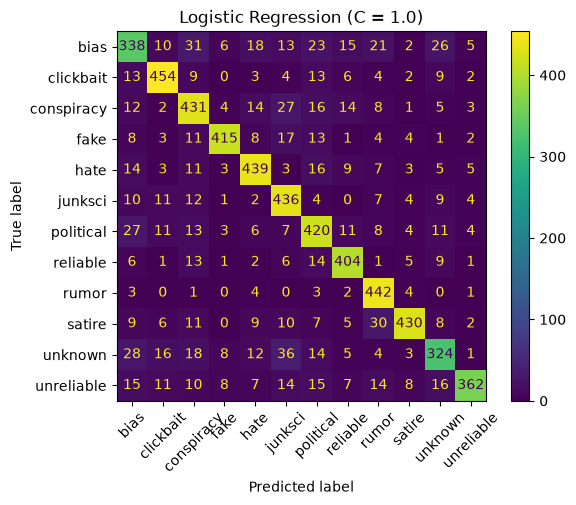

In [23]:
labels = lr.classes_

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels = labels
    )

display.plot()

plt.xticks(rotation = 45)
plt.title('Logistic Regression (C = 1.0)')
plt.show()


## Decision Tree 

In [24]:
dt = DecisionTreeClassifier()

In [25]:
pipeline_dt = Pipeline ([
    ("preprocessor", preprocessor),
    ("classifier", dt)
])

In [26]:
pipeline_dt.fit(X_train, y_train)
y_pred = pipeline_dt.predict(X_test)
print(f"held-out f1_macro: {f1_score(
    y_test,
    y_pred,
    average = "macro"
):.4f}")

KeyboardInterrupt: 

In [ ]:
results = cross_validate(
    pipeline_dt,
    X_train,
    y_train,
    cv = stratified_kfold_cv,
    scoring = metrics,
    return_train_score = True
)

KeyboardInterrupt: 

In [ ]:
for m in metrics:
    train_score = results[f"train_{m}"]
    test_score = results[f"test_{m}"]
    print(f"{m:16s} training data score = {train_score.mean():.4f} ± {train_score.std():.4f}")
    print(f"{m:16s} test data score = {test_score.mean():.4f} ± {test_score.std():.4f}")
    print(f"{m:16s} performance gap = {train_score.mean() - test_score.mean():.4f}")

accuracy         training data score = 0.9998 ± 0.0000
accuracy         test data score = 0.7254 ± 0.0067
accuracy         performance gap = 0.2744
precision_macro  training data score = 0.9998 ± 0.0000
precision_macro  test data score = 0.7273 ± 0.0071
precision_macro  performance gap = 0.2726
recall_macro     training data score = 0.9998 ± 0.0000
recall_macro     test data score = 0.7251 ± 0.0067
recall_macro     performance gap = 0.2748
f1_macro         training data score = 0.9998 ± 0.0000
f1_macro         test data score = 0.7257 ± 0.0068
f1_macro         performance gap = 0.2741


In [ ]:
print(dt.get_depth())

120


In [ ]:
lr_tuningC = LogisticRegression(
    max_iter = 1000,
    C = 1.5,
    random_state = 42
)

pipeline_lr_tuning = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", lr_tuningC),
])

results = cross_validate(
    pipeline_lr_tuning,
    X_train,
    y_train,
    cv = stratified_kfold_cv,
    scoring = metrics,
    return_train_score = True
    )

for m in metrics:
    train_score = results[f"train_{m}"]
    test_score = results[f"test_{m}"]
    print(f"{m:16s} training data score = {train_score.mean():.4f} ± {train_score.std():.4f}")
    print(f"{m:16s} test data score = {test_score.mean():.4f} ± {test_score.std():.4f}")
    print(f"{m:16s} performance gap = {train_score.mean() - test_score.mean():.4f}")

accuracy         training data score = 0.9866 ± 0.0007
accuracy         test data score = 0.8058 ± 0.0033
accuracy         performance gap = 0.1808
precision_macro  training data score = 0.9866 ± 0.0006
precision_macro  test data score = 0.8098 ± 0.0023
precision_macro  performance gap = 0.1768
recall_macro     training data score = 0.9866 ± 0.0006
recall_macro     test data score = 0.8057 ± 0.0033
recall_macro     performance gap = 0.1809
f1_macro         training data score = 0.9865 ± 0.0006
f1_macro         test data score = 0.8052 ± 0.0031
f1_macro         performance gap = 0.1814


In [ ]:
dt_tuning_md = DecisionTreeClassifier(
    max_depth = 50
)

pipeline_dt_tuning = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", dt_tuning_md),
])

results = cross_validate(
    pipeline_dt_tuning,
    X_train,
    y_train,
    cv = stratified_kfold_cv,
    scoring = metrics,
    return_train_score = True
    )

for m in metrics:
    train_score = results[f"train_{m}"]
    test_score = results[f"test_{m}"]
    print(f"{m:16s} training data score = {train_score.mean():.4f} ± {train_score.std():.4f}")
    print(f"{m:16s} test data score = {test_score.mean():.4f} ± {test_score.std():.4f}")
    print(f"{m:16s} performance gap = {train_score.mean() - test_score.mean():.4f}")

accuracy         training data score = 0.8365 ± 0.0106
accuracy         test data score = 0.6934 ± 0.0022
accuracy         performance gap = 0.1432
precision_macro  training data score = 0.8870 ± 0.0108
precision_macro  test data score = 0.7316 ± 0.0117
precision_macro  performance gap = 0.1554
recall_macro     training data score = 0.8364 ± 0.0106
recall_macro     test data score = 0.6930 ± 0.0021
recall_macro     performance gap = 0.1434
f1_macro         training data score = 0.8481 ± 0.0087
f1_macro         test data score = 0.7017 ± 0.0042
f1_macro         performance gap = 0.1464
